# Parameter ranges

Step 2 of `docs/unet-baseline-plan.md`, run with the real generator: pits filled with `richdem`, and
`K` adjusted with `m` (see `config.py`). The dataset is generated once, so its ranges must be right
first.

A range is good if:

- its low end still changes the terrain visibly within one run;
- its high end does not wear the terrain flat before the run ends.

Two numbers are tracked over each run:

- **change**: mean absolute height change since the start, as a fraction of the starting relief.
- **flat fraction**: the fraction of interior nodes with slope below 2%. Near 1 means worn flat.

Erosion parameters are given the way the generator draws them: `K_ref`, `D/K_ref`, `m`, and
`U/K_ref`.

In [1]:
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LightSource

from erosion_datagen.config import PROFILES
from erosion_datagen.simulate import erodibility, run_many

In [2]:
CFG = PROFILES["full"]
DEFAULTS = dict(K_ref=2e-4, D_over_K=1.0, m=0.4, U_over_K=0.0, period=128.0, persistence=0.5)
SHOW = [0, 5, 15, 30, 50]  # snapshot indices shown as pictures (snapshot i is step 10 * i)


def run(rows):
    """Simulate one run per dict in ``rows`` (keys as in DEFAULTS), in parallel, on terrain seed 0."""
    rows = [{**DEFAULTS, **row} for row in rows]
    col = {k: np.array([r[k] for r in rows], dtype=float) for k in DEFAULTS}
    params = {
        "K": erodibility(CFG, col["K_ref"], col["m"]),
        "D": col["K_ref"] * col["D_over_K"],
        "m": col["m"],
        "U": col["K_ref"] * col["U_over_K"],
        "period": col["period"],
        "persistence": col["persistence"],
        "terrain_seed": np.zeros(len(rows), dtype=np.int64),
    }
    start = time.perf_counter()
    out = [None] * len(rows)
    for i, snaps in run_many(CFG, params):
        out[i] = snaps
    print(f"{len(rows)} runs in {time.perf_counter() - start:.1f} s")
    return out


def change(snaps):
    return np.abs(snaps - snaps[0]).mean(axis=(1, 2)) / (snaps[0].max() - snaps[0].min())


def flat_fraction(snaps, threshold=0.02):
    gy, gx = np.gradient(snaps, CFG.cell_size, axis=(1, 2))
    return (np.hypot(gx, gy)[:, 1:-1, 1:-1] < threshold).mean(axis=(1, 2))


def hillshade(ax, z, title=""):
    light = LightSource(azdeg=315, altdeg=45)
    ax.imshow(light.shade(z, cmap=plt.cm.terrain, blend_mode="soft"), origin="lower")
    ax.set_title(title, fontsize=9)
    ax.set_axis_off()


def sweep(name, values):
    """Vary one parameter, others at DEFAULTS. Show pictures over time and the two measures."""
    results = run([{name: v} for v in values])
    fig, axes = plt.subplots(len(values), len(SHOW), figsize=(2.6 * len(SHOW), 2.6 * len(values)), layout="constrained")
    for row, value, snaps in zip(axes, values, results):
        for ax, s in zip(row, SHOW):
            hillshade(ax, snaps[s], f"{name}={value:g}, step {s * CFG.snapshot_every}")
    plt.show()
    steps = np.arange(len(results[0])) * CFG.snapshot_every
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5), layout="constrained")
    for value, snaps in zip(values, results):
        a.plot(steps, change(snaps), label=f"{name}={value:g}")
        b.plot(steps, flat_fraction(snaps), label=f"{name}={value:g}")
    a.set(xlabel="step", ylabel="change / starting relief", title="change")
    b.set(xlabel="step", ylabel="fraction of nodes", title="flat fraction (slope < 2%)", ylim=(0, 1))
    a.legend(fontsize=8)
    plt.show()
    return results

## 1. Erodibility `K_ref`

With pits filled, lakes drain, so terrain erodes faster than without pit handling. This sets the top
of the `K_ref` range.

5 runs in 2.6 s


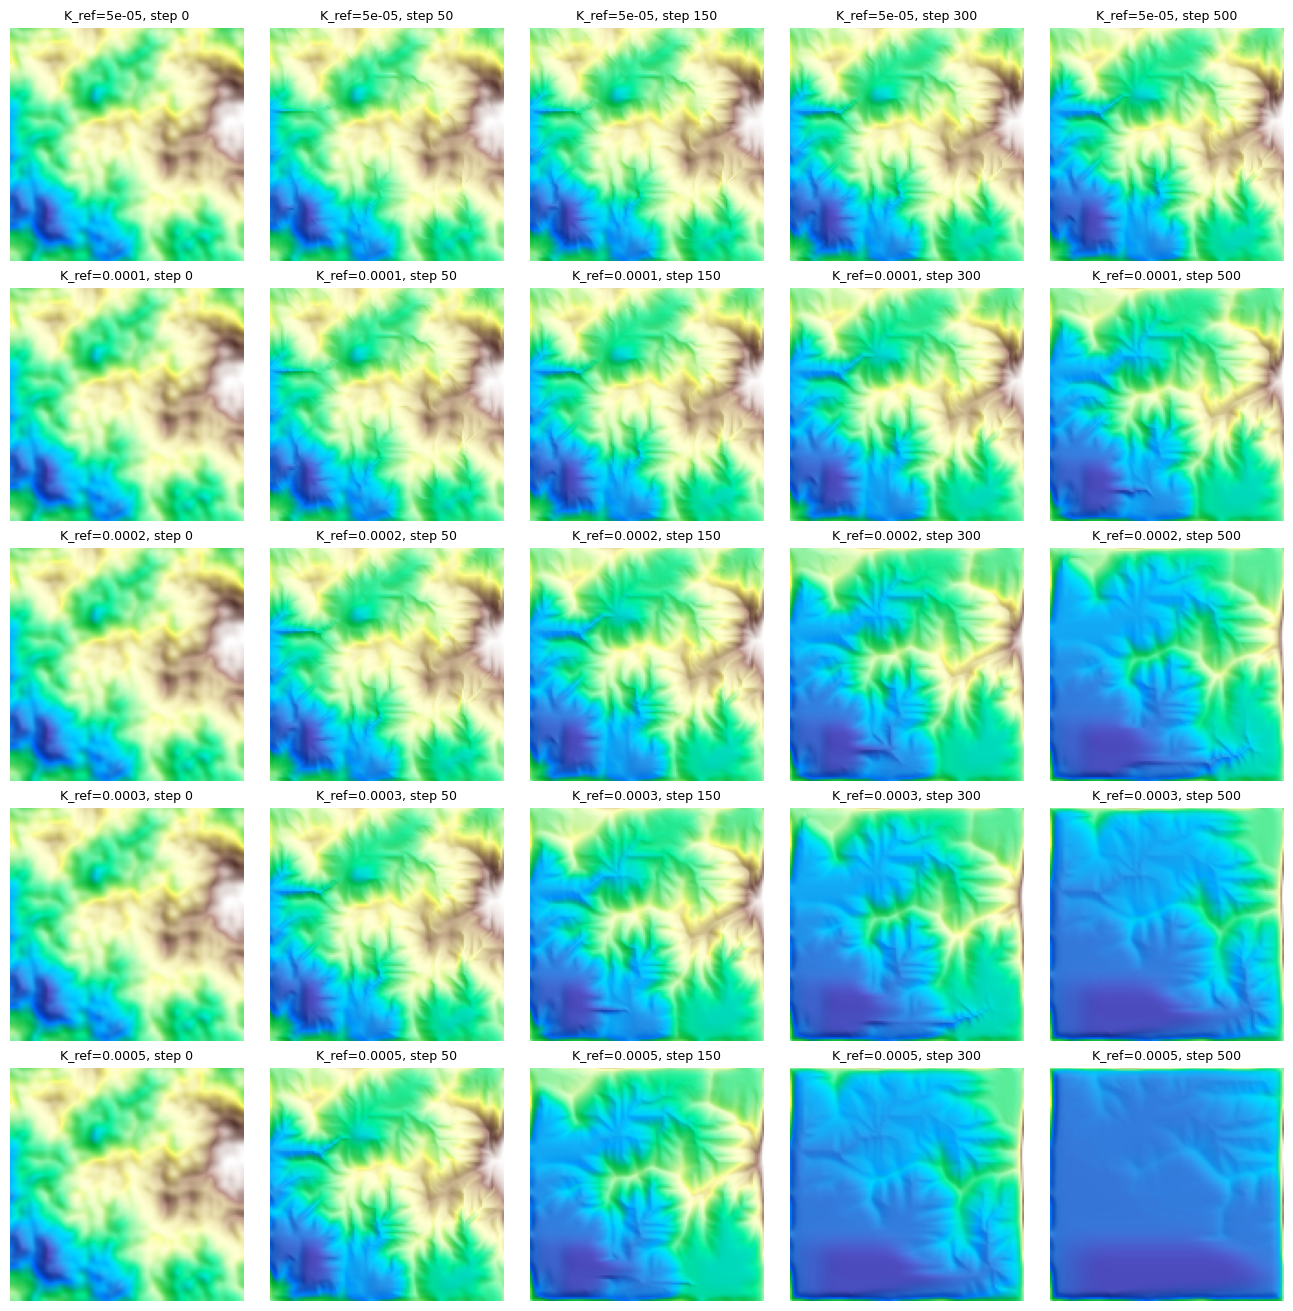

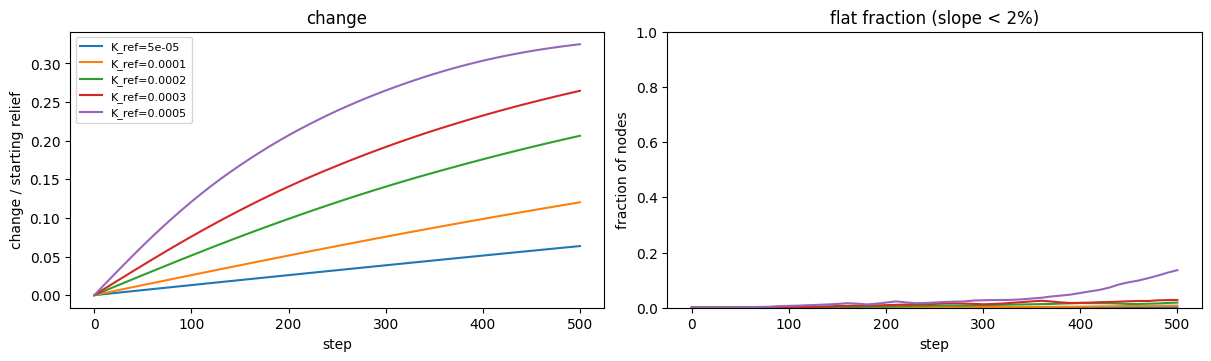

In [3]:
k_runs = sweep("K_ref", [5e-5, 1e-4, 2e-4, 3e-4, 5e-4])

## 2. Exponent `m`, with `K` adjusted

`K` is rescaled with `m` as `K = K_ref * A_ref^(m_ref - m)`, so that a node draining `A_ref`
erodes at the same rate for any `m`. Without this, `m = 0.6` erodes much more than `m = 0.3`.

`A_ref` sets where the rates match. Most nodes are hillslopes with small drainage area, so a large
`A_ref` over-corrects. The next cell measures the change at step 500 for several `A_ref`.
`config.py` uses the value that gives about equal change across the `m` range.

In [4]:
import dataclasses

ms = [0.3, 0.45, 0.6]
for a_ref in [30.0, 100.0, 300.0, 1000.0]:
    cfg = dataclasses.replace(CFG, A_ref=a_ref)
    K = erodibility(cfg, np.full(len(ms), DEFAULTS["K_ref"]), np.array(ms))
    params = dict(
        K=K, D=np.full(len(ms), DEFAULTS["K_ref"] * DEFAULTS["D_over_K"]), m=np.array(ms),
        U=np.zeros(len(ms)), period=np.full(len(ms), DEFAULTS["period"]),
        persistence=np.full(len(ms), DEFAULTS["persistence"]), terrain_seed=np.zeros(len(ms), dtype=np.int64),
    )
    out = dict(run_many(cfg, params))
    print(f"A_ref={a_ref:>6g}: change at step 500 for m = {ms}:", ", ".join(f"{change(out[i])[-1]:.3f}" for i in range(len(ms))))

A_ref=    30: change at step 500 for m = [0.3, 0.45, 0.6]: 0.208, 0.205, 0.197


A_ref=   100: change at step 500 for m = [0.3, 0.45, 0.6]: 0.228, 0.195, 0.161


A_ref=   300: change at step 500 for m = [0.3, 0.45, 0.6]: 0.245, 0.185, 0.130


A_ref=  1000: change at step 500 for m = [0.3, 0.45, 0.6]: 0.266, 0.175, 0.102


3 runs in 2.6 s


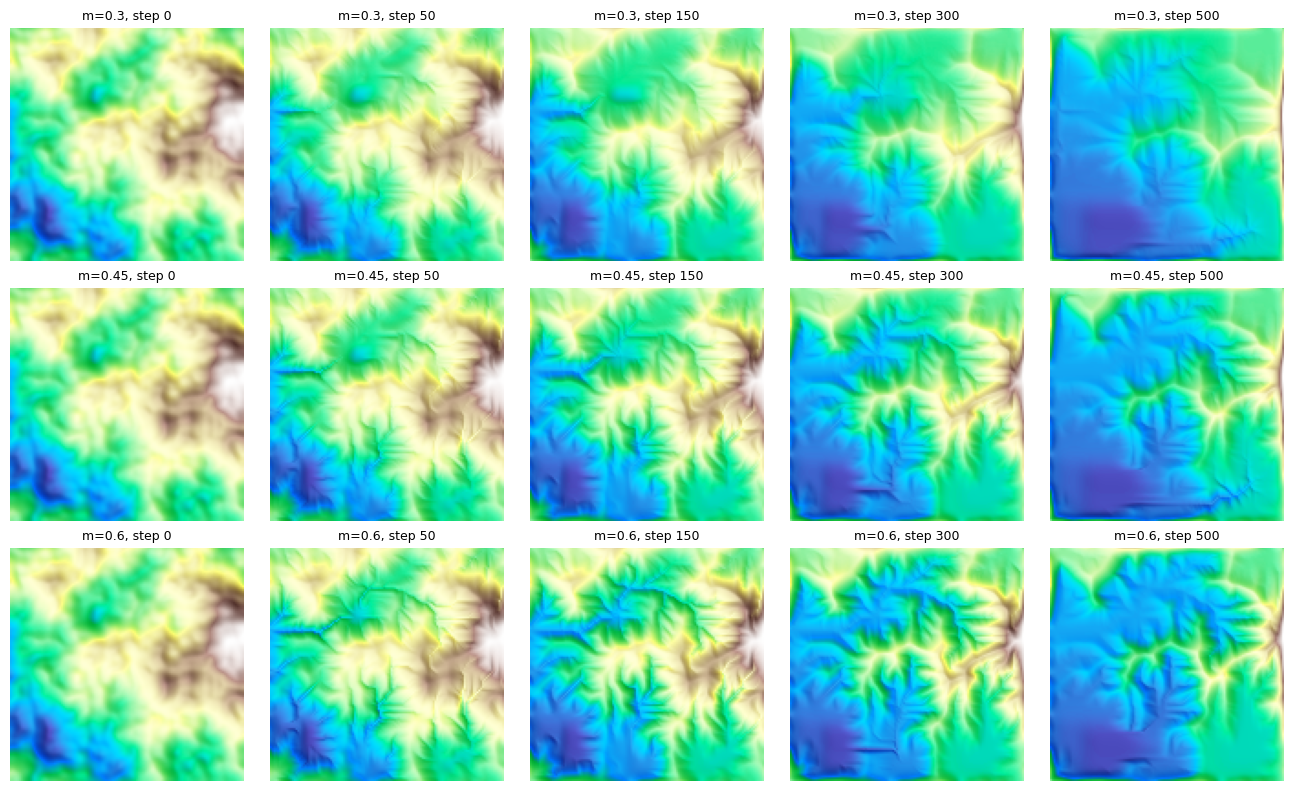

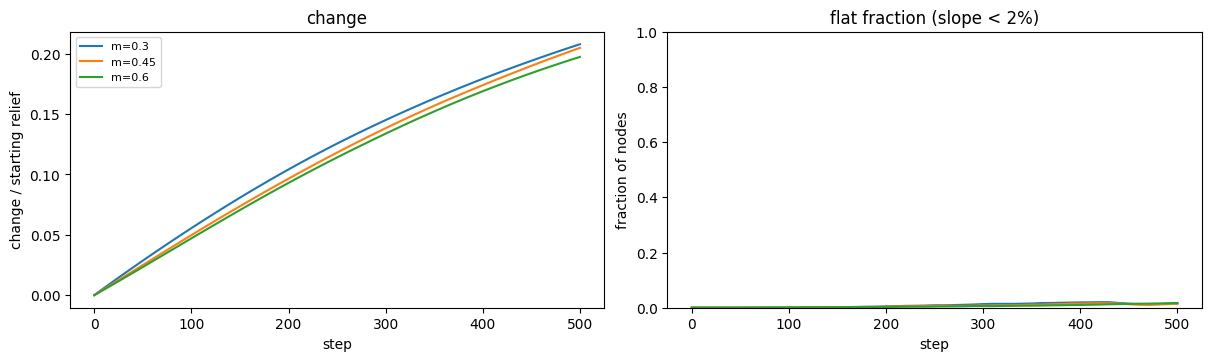

In [5]:
m_runs = sweep("m", ms)

## 3. Corners of the combined range

Every combination of the low and high ends of `K_ref`, `D/K_ref`, `m`, and `U/K_ref` (with `U/K_ref`
at 0 or its maximum). Terrain is at its defaults. Each picture is the final step.

`flat > 0.5 at step` is the first step where more than half the nodes are flat, or `-` if that never
happens.

16 runs in 4.8 s


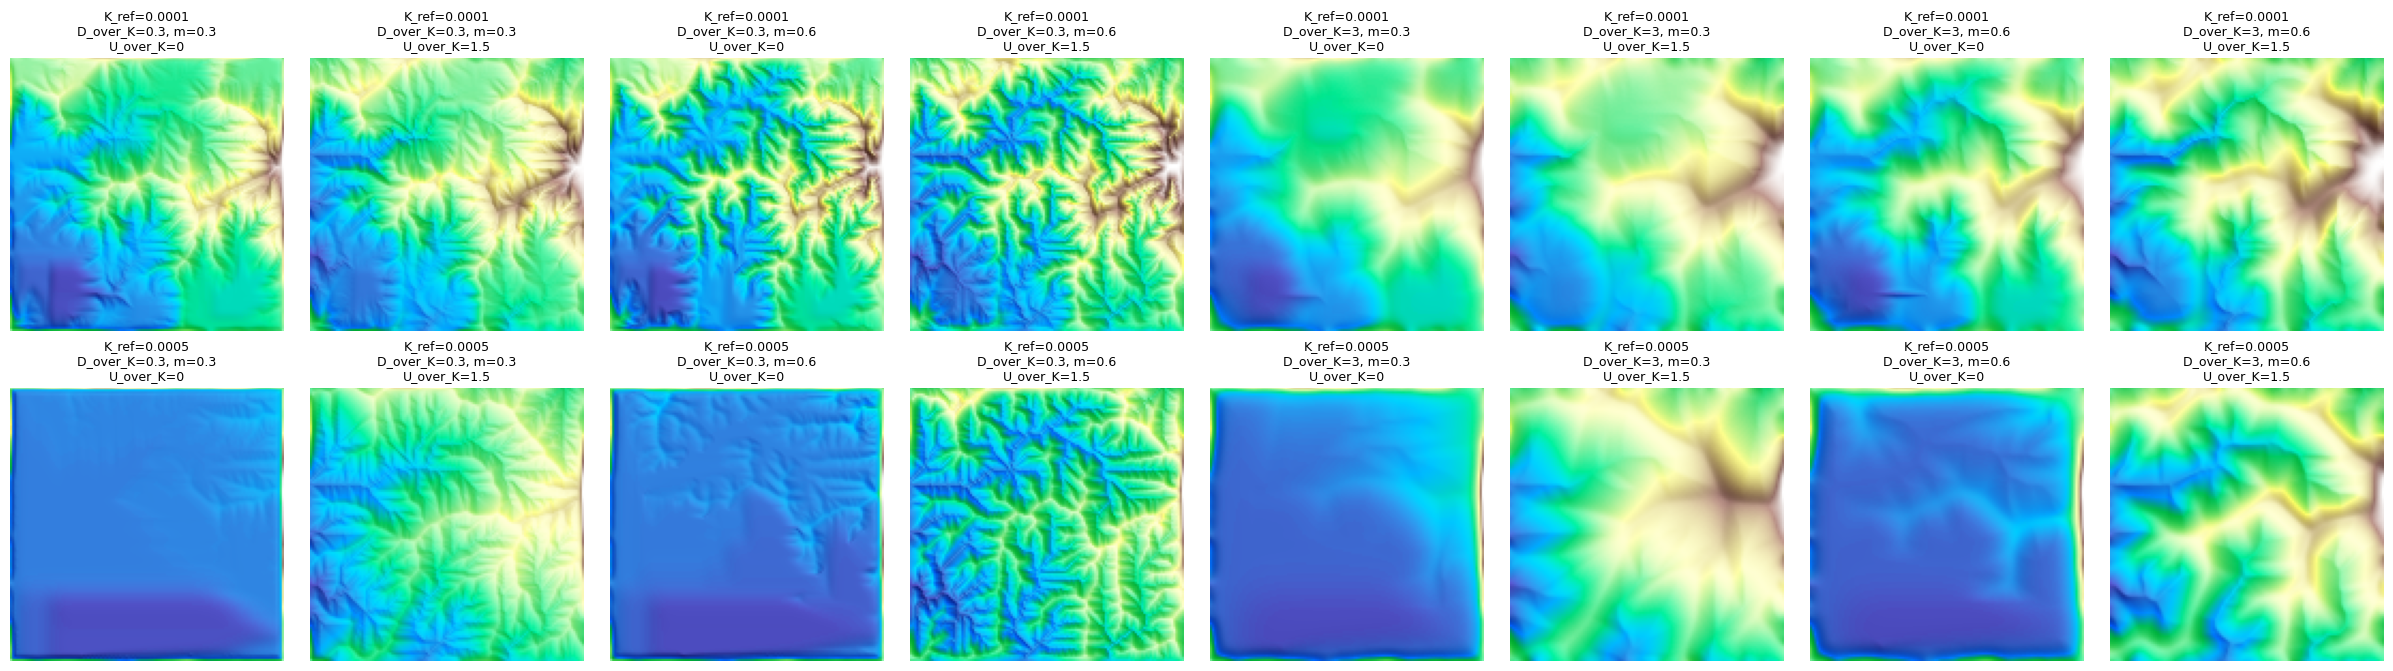

corner                                                         change   flat   flat > 0.5 at step
K_ref=0.0001, D_over_K=0.3, m=0.3, U_over_K=0                    0.15   0.02   -
K_ref=0.0001, D_over_K=0.3, m=0.3, U_over_K=1.5                  0.06   0.00   -
K_ref=0.0001, D_over_K=0.3, m=0.6, U_over_K=0                    0.14   0.01   -
K_ref=0.0001, D_over_K=0.3, m=0.6, U_over_K=1.5                  0.06   0.00   -
K_ref=0.0001, D_over_K=3, m=0.3, U_over_K=0                      0.11   0.00   -
K_ref=0.0001, D_over_K=3, m=0.3, U_over_K=1.5                    0.04   0.00   -
K_ref=0.0001, D_over_K=3, m=0.6, U_over_K=0                      0.10   0.00   -
K_ref=0.0001, D_over_K=3, m=0.6, U_over_K=1.5                    0.03   0.00   -
K_ref=0.0005, D_over_K=0.3, m=0.3, U_over_K=0                    0.34   0.30   -
K_ref=0.0005, D_over_K=0.3, m=0.3, U_over_K=1.5                  0.10   0.00   -
K_ref=0.0005, D_over_K=0.3, m=0.6, U_over_K=0                    0.34   0.15   -
K_ref=0.000

In [6]:
RANGES = dict(
    K_ref=CFG.K_ref,
    D_over_K=CFG.D_over_K,
    m=CFG.m,
    U_over_K=(0.0, CFG.U_over_K[1]),
)

corners = [dict(zip(RANGES, values)) for values in itertools.product(*RANGES.values())]
corner_runs = run(corners)


def label(row):
    return ", ".join(f"{k}={v:g}" for k, v in row.items())


fig, axes = plt.subplots(2, 8, figsize=(24, 6.6), layout="constrained")
for ax, row, snaps in zip(axes.flat, corners, corner_runs):
    hillshade(ax, snaps[-1], label(row).replace(", D", "\nD").replace(", U", "\nU"))
plt.show()

print(f"{'corner':<62} change   flat   flat > 0.5 at step")
for row, snaps in zip(corners, corner_runs):
    flat = flat_fraction(snaps)
    over = np.flatnonzero(flat > 0.5)
    when = f"{over[0] * CFG.snapshot_every}" if len(over) else "-"
    print(f"{label(row):<62} {change(snaps)[-1]:6.2f} {flat[-1]:6.2f}   {when}")

## 4. Terrain extremes

The harshest and mildest erosion corners, on the smallest and largest `period`.

4 runs in 2.7 s


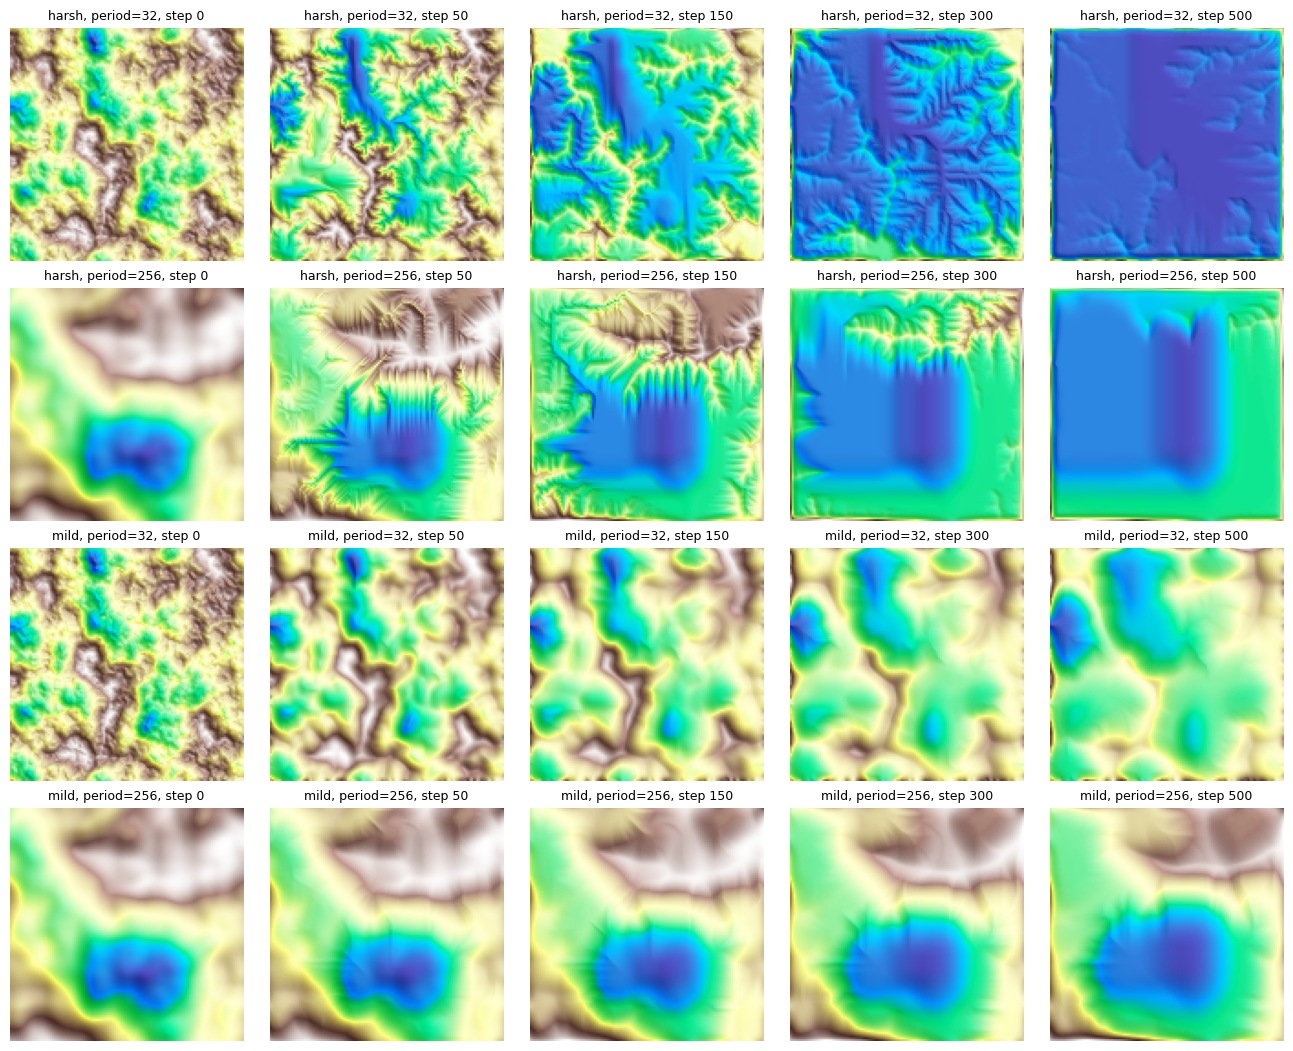

harsh, period=32         change 0.46  flat 0.27
harsh, period=256        change 0.38  flat 0.25
mild, period=32          change 0.17  flat 0.00
mild, period=256         change 0.13  flat 0.00


In [7]:
harsh = dict(K_ref=RANGES["K_ref"][1], D_over_K=RANGES["D_over_K"][0], m=RANGES["m"][1], U_over_K=0.0)
mild = dict(K_ref=RANGES["K_ref"][0], D_over_K=RANGES["D_over_K"][1], m=RANGES["m"][0], U_over_K=0.0)
cases = [dict(**e, period=p) for e in (harsh, mild) for p in CFG.period]
names = [f"{n}, period={p:g}" for n in ("harsh", "mild") for p in CFG.period]
terrain_runs = run(cases)
fig, axes = plt.subplots(len(cases), len(SHOW), figsize=(2.6 * len(SHOW), 2.6 * len(cases)), layout="constrained")
for row, name, snaps in zip(axes, names, terrain_runs):
    for ax, s in zip(row, SHOW):
        hillshade(ax, snaps[s], f"{name}, step {s * CFG.snapshot_every}")
plt.show()
for name, snaps in zip(names, terrain_runs):
    print(f"{name:<24} change {change(snaps)[-1]:.2f}  flat {flat_fraction(snaps)[-1]:.2f}")